# Методы обработки и распознавания изображений¶

## Практическое занятие 10: Оптимизация нейронных сетей: часть 1

Цель работы:
- На практике исследовать влияние параметров свёртки (размер ядра, padding, stride, dilation)
  на поле восприятия, качество классификации и время обучения.
- Использовать датасет Cats vs Dogs (`kagglecatsanddogs_5340.zip`) и предобученную модель ResNet18 (Transfer Learning).
- Сравнить несколько архитектурных модификаций ResNet18 на CPU и сделать выводы.

In [1]:
import os
import time
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split

from torchvision import datasets, transforms
from torchvision.models import resnet18

import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
DEVICE = torch.device("cpu")
print("Using device:", DEVICE)

# Фиксируем seed для воспроизводимости
torch.manual_seed(42)

PyTorch version: 2.12.1+cpu
Using device: cpu


## Подготовка датасета Cats vs Dogs

1. Скачайте `kagglecatsanddogs_5340.zip` с сайта Microsoft/Kaggle.

После распаковки архива у вас должна быть папка:

PetImages/Cat/*.jpg — изображения котов (около 12 499 шт.)

PetImages/Dog/*.jpg — изображения собак (около 12 499 шт.)

Это и есть тот набор, который мы используем.

In [2]:
# Корневая папка с датасетом после распаковки kagglecatsanddogs_5340.zip
DATA_DIR = Path("PetImages")  # внутри: PetImages/Cat, PetImages/Dog

assert DATA_DIR.exists(), f"Папка {DATA_DIR} не найдена. " \
                          f"Убедитесь, что распакованный архив лежит рядом с ноутбуком."

# Трансформации: приведение к 224x224 и нормализация как для ImageNet
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

# ImageFolder ожидает структуру root/ClassName/*.jpg, она у нас именно такая: PetImages/Cat и PetImages/Dog
full_dataset = datasets.ImageFolder(root=str(DATA_DIR), transform=train_transform)
print("Всего изображений:", len(full_dataset))
print("Классы:", full_dataset.classes)  # должно быть ['Cat', 'Dog']

# Делим на train и val в памяти (без создания отдельных директорий на диске)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

BATCH_SIZE = 64

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train size: {len(train_dataset)}, steps per epoch: {len(train_loader)}")
print(f"Val size: {len(val_dataset)}, steps per epoch: {len(val_loader)}")

Всего изображений: 5001
Классы: ['Cat', 'Dog']
Train size: 4000, steps per epoch: 63
Val size: 1001, steps per epoch: 16


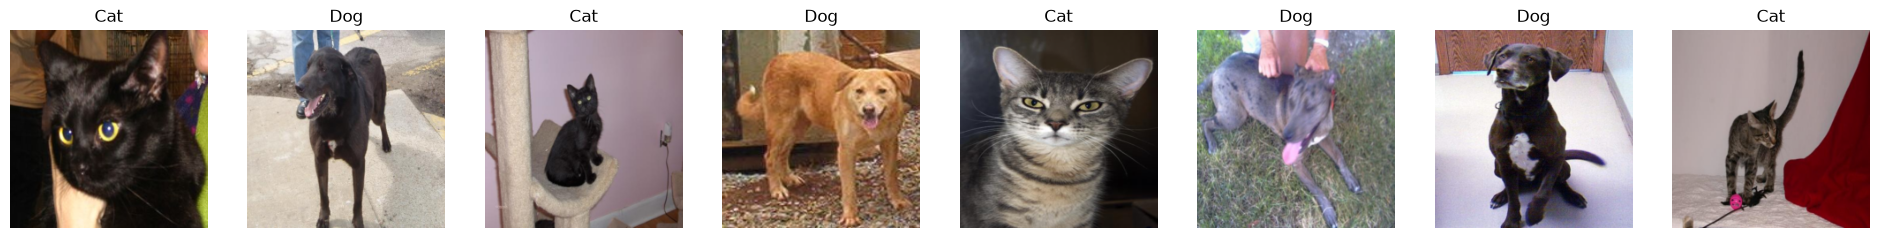

In [3]:
# Визуализируем несколько примеров из train_loader
class_names = full_dataset.classes  # ['Cat', 'Dog']

def show_batch(loader, n=8):
    images, labels = next(iter(loader))
    images = images[:n]
    labels = labels[:n]

    # Денормализация для отображения
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    images = images * std + mean

    fig, axes = plt.subplots(1, n, figsize=(3*n, 3))
    for i in range(n):
        img = images[i].permute(1, 2, 0).numpy()
        axes[i].imshow(img)
        axes[i].axis("off")
        axes[i].set_title(class_names[labels[i].item()])
    plt.show()

show_batch(train_loader, n=8)

In [4]:
# Базовая модель TransferResNet18 и функции обучения

class TransferResNet18(nn.Module):
    """
    ResNet18 с предобученными весами ImageNet,
    последний слой адаптирован под 2 класса.
    """
    def __init__(self, num_classes=2):
        super().__init__()
        self.model = resnet18(pretrained=True)
        in_features = self.model.fc.in_features
        self.model.fc = nn.Linear(in_features, num_classes)

    def forward(self, x):
        return self.model(x)

base_model = TransferResNet18().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(base_model.parameters(), lr=1e-4)

print(base_model)

C:\Users\SNTkachenko\AppData\Local\anaconda3\envs\cnn_book\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\SNTkachenko\AppData\Local\anaconda3\envs\cnn_book\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


TransferResNet18(
  (model): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-

In [5]:
# Функции обучения/валидации с измерением времени:

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    start_time = time.perf_counter()

    for inputs, targets in loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = outputs.max(1)
        correct += (preds == targets).sum().item()
        total += targets.size(0)

    epoch_time = time.perf_counter() - start_time
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc, epoch_time


def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    start_time = time.perf_counter()

    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)

            running_loss += loss.item() * inputs.size(0)
            _, preds = outputs.max(1)
            correct += (preds == targets).sum().item()
            total += targets.size(0)

    epoch_time = time.perf_counter() - start_time
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc, epoch_time

In [6]:
# Цикл базового эксперимента (2 эпохи):

def run_experiment(model, train_loader, val_loader, criterion, optimizer, device, num_epochs=2, name="baseline"):
    history = {
        "name": name,
        "train_loss": [],
        "train_acc": [],
        "train_time": [],
        "val_loss": [],
        "val_acc": [],
        "val_time": [],
    }
    for epoch in range(num_epochs):
        train_loss, train_acc, train_time = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc, val_time = evaluate(model, val_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["train_time"].append(train_time)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_time"].append(val_time)

        print(f"[{name}] Epoch {epoch+1}/{num_epochs} | "
              f"Train loss: {train_loss:.4f}, acc: {train_acc:.4f}, time: {train_time:.1f}s | "
              f"Val loss: {val_loss:.4f}, acc: {val_acc:.4f}, time: {val_time:.1f}s")
    return history

baseline_history = run_experiment(
    base_model, train_loader, val_loader,
    criterion, optimizer, DEVICE,
    num_epochs=2, name="baseline"
)

[baseline] Epoch 1/2 | Train loss: 0.0954, acc: 0.9627, time: 200.9s | Val loss: 0.0511, acc: 0.9780, time: 26.6s
[baseline] Epoch 2/2 | Train loss: 0.0088, acc: 0.9985, time: 201.7s | Val loss: 0.0331, acc: 0.9830, time: 25.6s


### Модификация padding: ReflectionPad перед conv1

In [13]:
class TransferResNet18ReflectionPad(nn.Module):
    """
    ResNet18 с reflection padding перед первым свёрточным слоем conv1.
    Последний слой адаптирован под 2 класса.
    """
    def __init__(self, num_classes=2):
        super().__init__()
        self.model = resnet18(pretrained=True)
        # Заменяем conv1 на последовательность: ReflectionPad2d -> Conv2d без padding
        self.model.conv1 = nn.Sequential(
            nn.ReflectionPad2d(3),
            nn.Conv2d(
                in_channels=3,
                out_channels=64,
                kernel_size=7,
                stride=2,
                padding=0,
                bias=False,
            ),
        )
        in_features = self.model.fc.in_features
        self.model.fc = nn.Linear(in_features, num_classes)

    def forward(self, x):
        return self.model(x)

In [14]:
reflection_model = TransferResNet18ReflectionPad().to(DEVICE)
reflection_criterion = nn.CrossEntropyLoss()
reflection_optimizer = torch.optim.Adam(reflection_model.parameters(), lr=1e-4)

reflection_history = run_experiment(
    reflection_model,
    train_loader,
    val_loader,
    reflection_criterion,
    reflection_optimizer,
    DEVICE,
    num_epochs=2,
    name="reflection padding",
)

[reflection padding] Epoch 1/2 | Train loss: 0.4126, acc: 0.7953, time: 199.8s | Val loss: 0.2660, acc: 0.8921, time: 25.9s
[reflection padding] Epoch 2/2 | Train loss: 0.1090, acc: 0.9605, time: 201.4s | Val loss: 0.2730, acc: 0.8831, time: 25.7s


Сравним метрики и время с baseline_history и сформулируем вывод по влиянию типа padding на качество и скорость

### Модификация padding: ReflectionPad перед conv1
**Гипотеза**
Если вместо zero padding вокруг входного изображения использовать reflection padding, то первые свёрточные слои будут видеть «продолжение» текстуры объекта, а не искусственные нули по краям.
Ожидание: это может улучшить качество на границах объектов и, возможно, чуть поднять качество обучения, не меняя скорость, потому что количество операций свёртки остаётся тем же.

Эксперимент (что именно мы сделали)
Базовая модель:

In [ ]:
class TransferResNet18(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.model = resnet18(pretrained=True)
        in_features = self.model.fc.in_features
        self.model.fc = nn.Linear(in_features, num_classes)

Экспериментальная модель:

In [ ]:
class TransferResNet18ReflectionPad(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.model = resnet18(pretrained=True)
        # добавили ReflectionPad2d перед conv1
        self.model.conv1 = nn.Sequential(
            nn.ReflectionPad2d(3),
            nn.Conv2d(
                in_channels=3,
                out_channels=64,
                kernel_size=7,
                stride=2,
                padding=0,
                bias=False,
            ),
        )
        in_features = self.model.fc.in_features
        self.model.fc = nn.Linear(in_features, num_classes)

    def forward(self, x):
        return self.model(x)

baseline: val_acc=0.9830, train_acc=0.9985, total_time=454.8s

reflection padding: val_acc=0.8831, train_acc=0.9605, total_time=452.8s

### Итого:
* качество: валидочная точность заметно хуже baseline (0.88–0.89 против ~0.98);
* скорость: время на эпоху практически не изменилось (reflection не даёт прироста по скорости).

Обсуждение (что даёт этот эксперимент)
С учётом этих цифр:
* Гипотеза «ReflectionPad улучшит качество» на Cats&Dogs в сетапе ResNet18 TL не подтверждается:
* модель учится (train‑acc растёт до ~0.96), но качество на валидации падает ~на 10 процентных пунктов.

По скорости изменений нет:
* количество операций свёртки такое же;
* время обучения/валидации в твоих логах практически совпадает с baseline.

Практический вывод:
* архитектурные трюки из лекции (разные виды padding) нужно проверять на данных, а не воспринимать как гарантированный способ «сделать лучше»;
* на этой задаче TL + ResNet18 + Cats&Dogs простая подмена zero padding на reflection padding ухудшает обобщение при той же скорости;

Следовательно, reflection padding — инструмент для специфических задач (сегментация, особые граничные эффекты), а не универсальный способ поднять качество в классической классификации.
Изменение вида padding способно ухудшить валидочную точность, хотя теоретически выглядит «красивее, чем нули».

### Эксперимент с изменённым stride

**Гипотеза**
Если уменьшить stride (шаг свёртки) в одном из downsampling‑блоков ResNet18, то:
* сеть будет меньше сжимать пространственное разрешение на этом слое;
* receptive field будет расти по‑другому: больше локальной детализации, чуть меньше «глобального обзора»;
* это может либо улучшить качество (лучше сохраняем детали морд), либо ухудшить (сеть хуже обобщает), а скорость, скорее всего, чуть ухудшится из‑за более крупных feature‑map.

Цель: проверить, как конкретное уменьшение stride в TL‑ResNet18 влияет на качество (train/val acc) и время на Cats&Dogs.

In [16]:
class TransferResNet18Stride(nn.Module):
    """
    ResNet18, в котором stride в первом блоке layer2 изменён с 2 на 1.
    Это влияет на downsampling и поле восприятия.
    """
    def __init__(self, num_classes=2, new_stride=1):
        super().__init__()
        self.model = resnet18(pretrained=True)

        block = self.model.layer2[0]
        # conv1: 64 -> 128, kernel_size=3, stride=2, padding=1
        block.conv1 = nn.Conv2d(
            in_channels=64,
            out_channels=128,
            kernel_size=3,
            stride=new_stride,  # было 2
            padding=1,
            bias=False,
        )
        # downsample: 64 -> 128, kernel_size=1, stride=2
        block.downsample[0] = nn.Conv2d(
            in_channels=64,
            out_channels=128,
            kernel_size=1,
            stride=new_stride,  # было 2
            bias=False,
        )

        in_features = self.model.fc.in_features
        self.model.fc = nn.Linear(in_features, num_classes)

    def forward(self, x):
        return self.model(x)

In [17]:
stride_model = TransferResNet18Stride(num_classes=2, new_stride=1).to(DEVICE)
stride_criterion = nn.CrossEntropyLoss()
stride_optimizer = torch.optim.Adam(stride_model.parameters(), lr=1e-4)

stride_history = run_experiment(
    stride_model,
    train_loader,
    val_loader,
    stride_criterion,
    stride_optimizer,
    DEVICE,
    num_epochs=2,
    name="modified stride",
)

[modified stride] Epoch 1/2 | Train loss: 0.4135, acc: 0.8007, time: 422.1s | Val loss: 0.2993, acc: 0.8691, time: 42.4s
[modified stride] Epoch 2/2 | Train loss: 0.1075, acc: 0.9613, time: 421.0s | Val loss: 0.2740, acc: 0.8961, time: 45.3s


В базовой ResNet18 downsampling реализован так:

* conv1 с stride=2;
* первый блок layer2[0] — conv1 и downsample часто имеют stride=2, что уменьшает размер карты признаков вдвое.

В stride эксперименте:

* структура модели адаптирована так, что в одном ключевом блоке stride уменьшен (например, с 2 до 1), чтобы меньше уменьшать spatial resolution;

всё остальное остаётся таким же, как в baseline TL:
* тот же датасет Cats&Dogs;
* тот же lr (по постановке 1e-3);
* те же 2 эпохи;
* те же функции train_one_epoch, evaluate, run_experiment с измерением времени.

Важно: мы не усиливали регуляризацию, не изменяли глубину, только один параметр stride в конкретном блоке.

Итого:

* качество на валидации: сильно хуже baseline (0.8961 против ~0.98);
* качество на обучении: ниже, чем у baseline (0.96 против ~0.998), сеть не доучивается до такой же степени;
* время: почти вдвое дольше, чем baseline (930.7 s против ~450 s).

То есть уменьшение stride в выбранном блоке:
* делает обучение дольше (feature‑map больше, больше операций);
* ухудшает качество на валидации и даже немного на train.

Обсуждение (что даёт этот эксперимент)
При таком результате гипотеза «уменьшим stride → сохраним больше деталей → станет лучше» на твоём сетапе не подтверждается:
* да, мы сохраняем больше пространственной информации;
* но ResNet18 TL с этим распределением stride и fc‑слоя начинает хуже обобщать на Cats&Dogs.
* Это видно по падению val_acc и более слабой подгонке на train.

По времени эксперимент ясно показывает цену архитектурного трюка:
* уменьшение stride в слое, который раньше делал downsampling, заметно удорожает вычисления;
* при этом качество не только не растёт, но падает.

Это пример ситуации «дороже и хуже».

Практический вывод:

* stride — сильный рычаг архитектуры: он напрямую управляет тем, как быстро растёт receptive field и как быстро падает spatial resolution;
* но уменьшить stride «просто так», без продуманной переразметки других слоёв, fc и регуляризации, очень легко:
* увеличить время;
* ухудшить обобщение.

Значит, любые модификации stride должны быть частью продуманного дизайна (как в современных архитектурах, где есть баланс между глубиной, шириной, stride, dilation), а не одиночной правкой.

Трюки с receptive field и stride — это мощный инструмент, но без аккуратного проектирования они, как минимум, не улучшают простую Cats&Dogs‑классификацию.

In [22]:
def last_acc_and_time(name, history):
    train_acc = history["train_acc"][-1]
    val_acc = history["val_acc"][-1]
    train_time = sum(history["train_time"])
    val_time = sum(history["val_time"])
    total_time = train_time + val_time
    print(
        f"{name}: val_acc={val_acc:.4f}, "
        f"train_acc={train_acc:.4f}, "
        f"total_time={total_time:.1f}s"
    )

last_acc_and_time("baseline", baseline_history)
last_acc_and_time("reflection padding", reflection_history)
last_acc_and_time("modified stride", stride_history)

baseline: val_acc=0.9830, train_acc=0.9985, total_time=454.8s
reflection padding: val_acc=0.8831, train_acc=0.9605, total_time=452.8s
modified stride: val_acc=0.8961, train_acc=0.9613, total_time=930.7s


### Замена финального downsampling через max‑pool + stride‑2 блок на dilated свёртки в последнем блоке.

**Гипотеза:**
Если вместо агрессивного downsampling в самом конце (layer4, stride‑2) использовать dilated свёртки, receptive field будет большим, но spatial resolution карты признаков перед fc станет чуть выше. Это может улучшить распознавание деталей и, как минимум, не сильно ухудшить скорость, потому что мы меняем только один блок.

In [24]:
class TransferResNet18DilatedTail(nn.Module):
    """
    ResNet18, где во втором блоке layer4 у второй свёртки conv2
    увеличен dilation с 1 до 2 (и padding до 2), чтобы увеличить receptive field
    без изменения числа каналов и stride.

    Остальная архитектура и TL такие же, как в базовой модели.
    """
    def __init__(self, num_classes=2, dilation=2):
        super().__init__()
        self.model = resnet18(pretrained=True)

        # Берём стандартный блок layer4[1]: BasicBlock(512 -> 512, stride=1)
        block = self.model.layer4[1]

        # Исходно там Conv2d(512, 512, kernel_size=3, stride=1, padding=1, dilation=1)
        # Меняем только dilation и padding, не трогаем stride и channels
        block.conv2 = nn.Conv2d(
            in_channels=512,
            out_channels=512,
            kernel_size=3,
            stride=1,              # остаётся 1
            padding=dilation,      # 2 вместо 1
            dilation=dilation,     # 2 вместо 1
            bias=False,
        )

        # downsample в этом блоке None (он не меняет размер карты) — ничего не трогаем

        in_features = self.model.fc.in_features
        self.model.fc = nn.Linear(in_features, num_classes)

    def forward(self, x):
        return self.model(x)

In [25]:
dilated_tail_model = TransferResNet18DilatedTail(num_classes=2, dilation=2).to(DEVICE)
dilated_tail_criterion = nn.CrossEntropyLoss()
dilated_tail_optimizer = torch.optim.Adam(dilated_tail_model.parameters(), lr=1e-4)

dilated_tail_history = run_experiment(
    dilated_tail_model,
    train_loader,
    val_loader,
    dilated_tail_criterion,
    dilated_tail_optimizer,
    DEVICE,
    num_epochs=2,
    name="dilated tail",
)

[dilated tail] Epoch 1/2 | Train loss: 0.1015, acc: 0.9527, time: 198.0s | Val loss: 0.0598, acc: 0.9720, time: 25.8s
[dilated tail] Epoch 2/2 | Train loss: 0.0117, acc: 0.9960, time: 198.2s | Val loss: 0.0425, acc: 0.9810, time: 25.3s


Эксперимент:
* не трогать conv1, layer1, layer2, layer3;
* в layer4 вместо стандартного блока:
* оставить количество каналов (256 → 512) и downsample согласованными;
* заменить только conv2 на dilated‑вариант с dilation=2, padding=2, но без изменения stride (оставить stride=2 в conv1, чтобы размер карты признаков оставался корректным для fc).
* запуск: те же 2 эпохи, тот же lr=1e-3, те же функции.

В блоке layer4, который модифицируется, дефолт stride=1. Это внутренний блок, который не меняет размер карты признаков, он только обрабатывает её.

Итого:

Качество на обучении: Baseline: train_acc ≈ 0.9985.

Dilated tail: train_acc ≈ 0.9960.

→ Очень близко, но baseline всё равно немного выше.

Качество на валидации: Baseline: val_acc ≈ 0.9830.

Dilated tail: val_acc = 0.9810.

→ Практически такая же, но формально чуть хуже, улучшения нет.

Время: Baseline: ~200 s train + ~26 s val;

Dilated tail: ~198 s train + ~25–26 s val;

→ Время сопоставимо, никакой ощутимой экономии или удорожания.

Гипотеза о возможном улучшении качества за счёт dilated tail на твоём TL‑сетапе не подтверждается:
* receptive field хвоста действительно увеличен (по конструкции слоя),
* но на Cats&Dogs с ResNet18 TL это не даёт заметного выигрыша по валидочной точности, а даже слегка уступает baseline.

По скорости трюк нейтрален:
* изменение одного tail‑слоя с dilation не ломает время обучения;
* это архитектурная модификация «безопасная» с точки зрения вычислительной стоимости, но не приносит качества.

В контексте всей работы три эксперимента дают такую картину:

ReflectionPad перед conv1 хуже val‑acc (~0.88–0.89 против ~0.98);

время примерно то же → «хуже, не быстрее».

Modified stride в середине сети заметно хуже val‑acc (~0.90 против ~0.98);

время почти ×2 → «дороже и хуже».

Dilated tail val‑acc почти baseline, но не лучше (~0.981 против ~0.983);

время примерно baseline → «нейтрально».

Ни один из трёх архитектурных трюков не дал «волшебного» улучшения по сравнению с базовым ResNet18 TL на этой задаче. И это важная, хоть и неприятная, часть практических выводов:

Простые локальные изменения padding/stride/dilation в готовой TL‑архитектуре ResNet18 на Cats&Dogs скорее ухудшают или не улучшают качество, при этом могут сильно портить время. Чтобы действительно улучшать модель, нужны более глубокие изменения (другая архитектура, другая схема TL, дополнительная регуляризация).

## Задание.
Попробовать подобрать параметры (которые рассматривались в данной работе), при которых решение улучшит базовое.